# Can we recover a known place field from simulated spikes?

**Question:** How closely can a firing-rate map recover a known place field
after repeated runs along a track, and what can we estimate from only 2 s?

Simulate six neurons with known place fields, estimate their firing-rate maps,
and measure errors in field location and map shape. Knowing the generating
fields lets us check the analysis rather than judge a map only by appearance.

**You will need:** A chosen track layout, a movement pattern and firing-rate
models. We define all three below; no data download is needed.

**Estimated time**: 15-20 minutes

**Prerequisites**: [Spatial rate maps](02_spatial_rate_maps.ipynb).

In [1]:
import sys
from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from neurospatial import Environment
from neurospatial.encoding import compute_spatial_rates
from neurospatial.simulation import (
    PlaceCellModel,
    SimulationSession,
    generate_population_spikes,
    simulate_trajectory_laps,
    validate_simulation,
)

_here = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
if not (_here / "_style.py").exists():
    _here = _here / "examples"
if str(_here) not in sys.path:
    sys.path.insert(0, str(_here))
from _style import OKABE_ITO, apply_style

apply_style(figsize=(11, 5))

## 1. Set the place fields and repeated track runs

Use a 100 cm track with 2 cm bins. The simulated animal makes ten one-way
runs, alternating direction, at about 15 cm/s. Each neuron has a Gaussian
place field: a preferred location, an 8 cm standard deviation, a 20 Hz peak
and a 0.1 Hz baseline. The model has the same tuning in both running directions.

Movement and spike generation use separate random streams. Fixing their seeds
makes the example reproducible; the six field centers are chosen explicitly.

In [2]:
env = Environment.from_grid_mask(
    np.ones(50, dtype=bool), grid_edges=(np.linspace(0.0, 100.0, 51),)
)
env = env.with_metadata(units="cm")
trajectory_stream, spike_stream = np.random.SeedSequence(2026).spawn(2)
trajectory_seed = int(trajectory_stream.generate_state(1)[0])
spike_seed = int(spike_stream.generate_state(1)[0])
positions, times = simulate_trajectory_laps(
    env,
    n_laps=10,
    speed_mean=15.0,
    speed_std=2.0,
    sampling_frequency=50.0,
    pause_duration=0.5,
    seed=trajectory_seed,
)
unit_ids = np.array([101, 104, 109, 112, 118, 123])
models = [
    PlaceCellModel(
        env,
        center=np.array([center]),
        width=8.0,
        max_rate=20.0,
        baseline_rate=0.1,
    )
    for center in np.linspace(10.0, 90.0, len(unit_ids))
]
spike_times = generate_population_spikes(
    models,
    times,
    positions,
    refractory_period=0.0,
    seed=spike_seed,
    show_progress=False,
)
session = SimulationSession(
    env=env,
    positions=positions,
    times=times,
    spike_times=spike_times,
    models=models,
    unit_ids=unit_ids,
    ground_truth={
        int(label): model.ground_truth
        for label, model in zip(unit_ids, models, strict=True)
    },
    metadata={"trajectory_seed": trajectory_seed, "spike_seed": spike_seed},
)
print(f"{len(times)} tracked samples over {times[-1]:.1f} s; {len(models)} units")
print(f"Simulated unit identifiers: {session.unit_ids.tolist()}")

3716 tracked samples over 74.3 s; 6 units
Simulated unit identifiers: [101, 104, 109, 112, 118, 123]


Given the sampled position, each neuron emits spikes according to a Poisson
process with its local firing rate. We set the refractory period to zero so
that spike generation follows this model exactly between position samples.
A positive refractory period would remove closely spaced candidate spikes
and lower the observed rates. This simulation omits tuning changes, spike
sorting errors and interactions between neurons.

## 2. Check how much time was spent in each location

Estimate rates with 4 cm smoothing and require 0.25 s of occupancy per bin.
First inspect the trajectory and occupancy. Repeated runs should sample the
full track; a known field cannot be recovered in a location that was never
visited or had too little observation time.

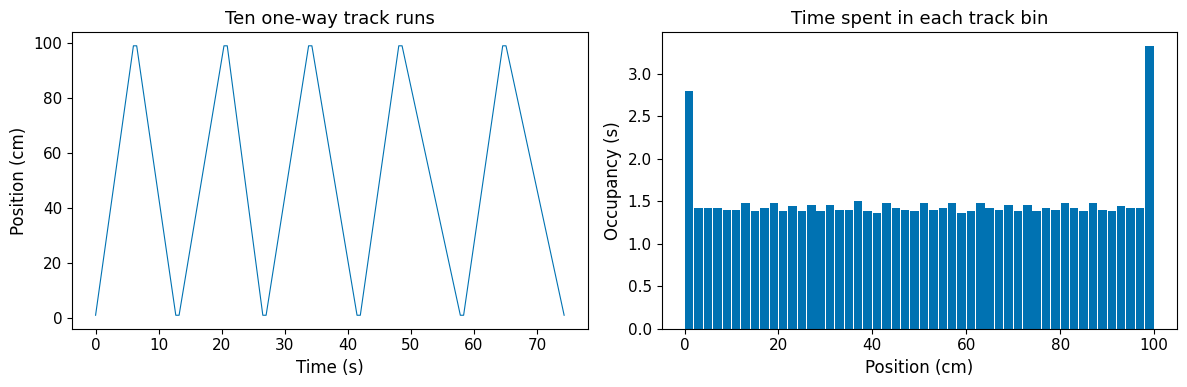

Bins with at least 0.25 s occupancy: 50 / 50


In [3]:
recording_window = (float(times[0]), float(times[-1]))
rates = compute_spatial_rates(
    env,
    session.spike_times,
    times,
    positions,
    unit_ids=unit_ids,
    bandwidth=4.0,
    min_occupancy=0.25,
    spike_window=recording_window,
)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(times, positions[:, 0], lw=0.8)
axes[0].set(xlabel="Time (s)", ylabel="Position (cm)", title="Ten one-way track runs")
axes[1].bar(env.bin_centers[:, 0], rates.occupancy, width=1.8)
axes[1].set(
    xlabel="Position (cm)", ylabel="Occupancy (s)", title="Time spent in each track bin"
)
fig.tight_layout()
plt.show()
print(
    f"Bins with at least 0.25 s occupancy: {rates.spatial_support.sum()} / {env.n_bins}"
)

All 50 bins have enough occupancy in this recording. The repeated sweeps in
the position plot show how that coverage was obtained. We can now compare
firing-rate estimates across the full track.

## 3. Compare estimated and true place fields

Dashed curves show the known firing rates at the track-bin centers. Solid
curves show estimates from spikes and occupancy. Random spike counts and
smoothing change field height and width, so exact agreement is not expected.
A bin with too little occupancy would have a missing rate, not a zero rate.

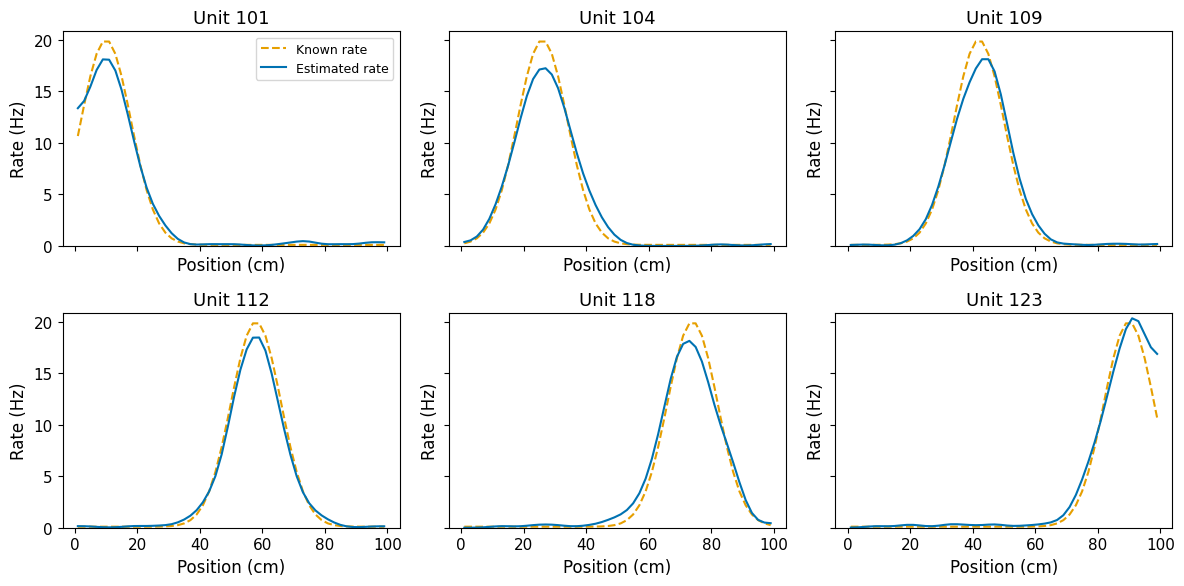

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(12, 6), sharex=True, sharey=True)
for row, (model, label, ax) in enumerate(zip(models, unit_ids, axes.flat, strict=True)):
    ax.plot(
        env.bin_centers[:, 0],
        model.firing_rate(np.zeros(len(env.bin_centers)), env.bin_centers),
        color=OKABE_ITO[1],
        ls="--",
        label="Known rate",
    )
    ax.plot(env.bin_centers[:, 0], rates.firing_rates[row], label="Estimated rate")
    ax.set(
        title=f"Unit {label}",
        xlabel="Position (cm)",
        ylabel="Rate (Hz)",
        ylim=(0, None),
    )
axes.flat[0].legend(fontsize=9)
fig.tight_layout()
plt.show()

The estimated fields lie near the known centers and retain their overall
shape. Compare both location and shape: a correctly located peak alone would
not establish that the rest of the firing-rate map was recovered.

## 4. Measure errors in field location and shape

Set two criteria: the estimated peak must be within 4 cm of the known center,
and the correlation between estimated and known maps must be at least 0.7.
`validate_simulation` reports these measurements for each unit. Correlation
uses bins where both maps have finite values. A unit is `not_evaluable` if a
required measurement cannot be made, for example because no rate bins remain.
These criteria check recovery in this simulation; they do not classify
recorded neurons as place cells or test significant spatial tuning.

In [5]:
validation_settings = {
    "bandwidth": 4.0,
    "min_occupancy": 0.25,
    "max_center_error": 4.0,
    "min_correlation": 0.7,
}
report = validate_simulation(
    session, spike_window=recording_window, **validation_settings
)


def print_unit_report(validation):
    """Show each unit's recovery measurements, including unavailable results."""
    print("Unit  Spikes  Peak error (cm)  Correlation  Status          Reason")
    for row, label in enumerate(validation["unit_ids"]):
        print(
            f"{label:4d}  {validation['spike_counts'][row]:6d}  "
            f"{validation['center_errors'][row]:15.2f}  "
            f"{validation['correlations'][row]:11.3f}  "
            f"{validation['unit_status'][row]:14s}  "
            f"{validation['skip_reasons'][row] or '-'}"
        )
    print(
        f"Units with both measurements: "
        f"{validation['n_evaluated']} / {validation['n_selected']}"
    )
    print(f"Every selected unit passed both criteria: {validation['passed']}")


print_unit_report(report)

Unit  Spikes  Peak error (cm)  Correlation  Status          Reason
 101     280             1.00        0.996  passed          -
 104     287             1.00        0.992  passed          -
 109     290             1.00        0.993  passed          -
 112     276             1.00        0.999  passed          -
 118     298             1.00        0.993  passed          -
 123     322             1.00        0.986  passed          -
Units with both measurements: 6 / 6
Every selected unit passed both criteria: True


In this run, all six peak-location errors are 1 cm and map correlations range
from about 0.99 to 1.00. All six meet the stated criteria. This is one recording
generated under the chosen model, not a guarantee for other firing rates,
field widths or movement patterns.

## 5. What can we estimate from only 2 seconds?

Repeat the analysis using the first 2 s, chosen in advance, with the same
occupancy requirement and smoothing. Crop spikes and position together and
retain every unit, including those with no spikes. This deliberately short
example demonstrates insufficient data; it does not estimate how recording
duration affects performance over a range of sample sizes.

In [6]:
short_samples = times < 2.0
short_times = times[short_samples]
short_window = (float(short_times[0]), float(short_times[-1]))
short_session = replace(
    session,
    times=short_times,
    positions=positions[short_samples],
    spike_times=[
        train[(train >= short_window[0]) & (train < short_window[1])]
        for train in spike_times
    ],
)
short_report = validate_simulation(
    short_session, spike_window=short_window, **validation_settings
)
print_unit_report(short_report)
short_occupancy = env.occupancy(
    short_times, short_session.positions, return_seconds=True
)
print(f"Bins visited in the short window: {(short_occupancy > 0).sum()} / {env.n_bins}")

Unit  Spikes  Peak error (cm)  Correlation  Status          Reason
 101      20              nan          nan  not_evaluable   no_finite_rate_bins
 104      20              nan          nan  not_evaluable   no_finite_rate_bins
 109       1              nan          nan  not_evaluable   no_finite_rate_bins
 112       0              nan          nan  not_evaluable   no_spikes
 118       0              nan          nan  not_evaluable   no_spikes
 123       0              nan          nan  not_evaluable   no_spikes
Units with both measurements: 0 / 6
Every selected unit passed both criteria: False
Bins visited in the short window: 17 / 50


/var/folders/5c/vh9h5cyd3p71_g3cw0zjnc_m0000gn/T/ipykernel_35373/2747758763.py:13: UserWarning: min_occupancy=0.25 s masks ALL 17 occupied bins (the highest occupancy is 0.14 s), so the rate map will be empty (all-NaN, or all-fill_value). min_occupancy is a threshold in SECONDS -- this usually means it is too large for this session. Lower it (or use the default 0.0 for no occupancy masking).
  short_report = validate_simulation(
/var/folders/5c/vh9h5cyd3p71_g3cw0zjnc_m0000gn/T/ipykernel_35373/2747758763.py:13: UserWarning: No cells could be fully validated (6 selected). Inspect skip_reasons and spike_counts for unavailable metrics.
  short_report = validate_simulation(


The animal visits only part of the track. No bin reaches the unchanged
0.25 s occupancy requirement, so none of the six units can be evaluated.
Some have no spikes; others have spikes but no rate bins with enough
occupancy (`no_finite_rate_bins`). These are unavailable measurements, not
evidence that the known place fields have disappeared. Lowering the occupancy
requirement would change the analysis and would not create more observations.

## Use your own recording

Use simulation to check an analysis under conditions resembling your
experiment: track layout, speed, number of runs, tracking frequency, field
width and firing rate. The true fields of recorded neurons are unknown;
simulated fields provide a reference under explicit assumptions about them.
The helpers `linear_track_session()` and `open_field_session()` can build a
complete simulated recording when you do not need custom movement or fields.

To assess reliability, repeat independent spike draws or trajectories and
report the spread of errors and the fraction that cannot be evaluated. Choose
analysis settings on separate simulations before evaluating recovery. Keep
failed and unavailable outcomes in the report rather than selecting favorable
seeds. Next, ask whether population spikes can predict new positions in
[position decoding](06_position_decoding.ipynb).